In [49]:
# ===== SEL IDENTITAS - JANGAN DIHAPUS, HARUS SEL PERTAMA =====
import sys, platform, hashlib, datetime, zoneinfo
import sys
import platform
import hashlib
import datetime
import zoneinfo

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

NAMA = 'Nor Rahman Maulana'
NIM = '244107020056' # ganti dengan NIM Anda

N = int(NIM[-3:])

PARAM = {
    'bins' : 2 ** ((N % 4) + 3),
    'clip' : round(1.0 + (N % 5) * 0.5, 1),
    'tile' : (N % 4) + 2,
    'L' : 2 ** ((N % 3) + 1),
}

waktu = datetime.datetime.now(
    zoneinfo.ZoneInfo('Asia/Jakarta')
)

print('NAMA :', NAMA)
print('NIM :', NIM, '| N =', N)

for k, v in PARAM.items():
    print('%-6s :' % k, v)

print('WAKTU :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())

kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')

print(
    'TOKEN :',
    hashlib.sha256(kunci.encode()).hexdigest()[:16]
)

NAMA : Nor Rahman Maulana
NIM : 244107020056 | N = 56
bins   : 8
clip   : 1.5
tile   : 2
L      : 8
WAKTU : 2026-10-02 00:12:35 WIB
SISTEM : 3.14.6 Windows-11-10.0.26200-SP0
TOKEN : ec2540cb0b5503ae


In [50]:
CONTOH = 'Lenna.png'

KTM1A = 'KTM1a.jpg'
KTM1B = 'KTM1b.jpeg'
KTM1C = 'KTM1c.jpg'
KTM1D = 'KTM1d.jpg'


In [51]:
import os

print('\n=== CEK FILE ===')

print(
    'Lena.png  :',
    os.path.exists(CONTOH)
)

print(
    'KTM1a.jpg :',
    os.path.exists(KTM1A)
)

print(
    'KTM1b.jpg :',
    os.path.exists(KTM1B)
)

print(
    'KTM1c.jpg :',
    os.path.exists(KTM1C)
)

print(
    'KTM1d.jpg :',
    os.path.exists(KTM1D)
)



=== CEK FILE ===
Lena.png  : True
KTM1a.jpg : False
KTM1b.jpg : True
KTM1c.jpg : False
KTM1d.jpg : False


In [52]:
def histogram_manual(img, L=256):

    h = np.zeros(
        L,
        dtype=np.int64
    )

    for y in range(img.shape[0]):

        for x in range(img.shape[1]):

            h[img[y, x]] += 1

    return h

In [53]:
def floyd_steinberg(gray, L=2):

    img = gray.astype(
        np.float32
    ).copy()

    step = 255.0 / (L - 1)

    H, W = img.shape

    for y in range(H):

        for x in range(W):

            lama = img[y, x]

            baru = (
                np.round(
                    lama / step
                ) * step
            )

            img[y, x] = baru

            error = lama - baru

            # kanan
            if x + 1 < W:
                img[y, x + 1] += (
                    error * 7 / 16
                )

            # kiri bawah
            if x > 0 and y + 1 < H:
                img[y + 1, x - 1] += (
                    error * 3 / 16
                )

            # bawah
            if y + 1 < H:
                img[y + 1, x] += (
                    error * 5 / 16
                )

            # kanan bawah
            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += (
                    error * 1 / 16
                )

    return np.clip(
        img,
        0,
        255
    ).astype(np.uint8)

<BarContainer object of 256 artists>

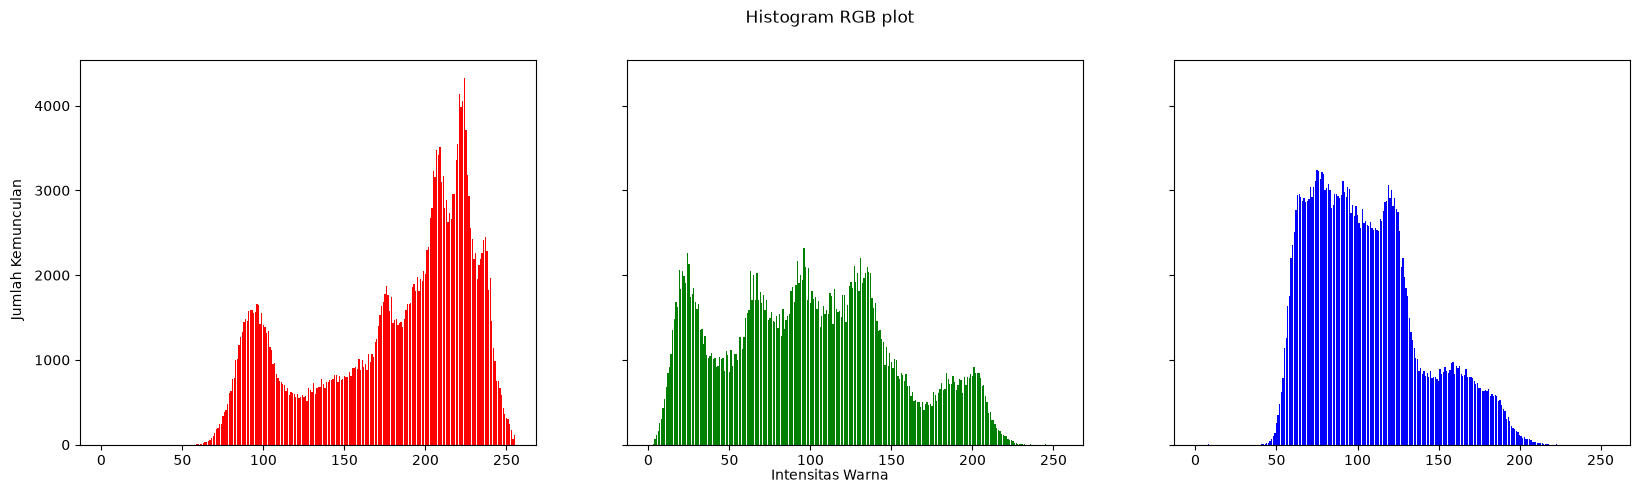

In [54]:
#Membuat histogram image (manual)
img = cv.imread('lenna.png')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)
names = np.arange(256)

red = [0]*256
green = [0]*256
blue = [0]*256

for y in range(0, height):
    for x in range(0, width):
        red[img[y][x][0]] += 1
        green[img[y][x][1]] += 1
        blue[img[y][x][2]] += 1

names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=[20,5], sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')

axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')

1. Buatlah histogram citra yang sama menggunakan library NumPy, yaitu numpy.histogram, dan juga cv.calcHist. Bandingkan ketiganya dengan menghitung selisih maksimum antar hasil. Selisihnya harus nol; tampilkan pembuktiannya pada lena.jpg lebih dulu, kemudian ulangi pada KTM1b.jpg.
2. Gambarkan histogram ternormalisasi p(j) dan kurva CDF untuk KTM1a.jpg sampai KTM1d.jpg dalam satu figure 2 x 2. Jelaskan perbedaan bentuk kurva CDF antara citra paling gelap dan citra paling terang milik Anda, lalu kaitkan dengan kondisi pencahayaan saat akuisisi pada Pertemuan 2. 
3. Ulangi histogram KTM1b.jpg dengan jumlah bin sebesar PARAM['bins'] dan dengan 256 bin. Tampilkan keduanya berdampingan dan jelaskan informasi apa yang hilang ketika jumlah bin dikurangi. 

In [55]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

PARAM = {
    'bins': 16
}

def read_gray(filename):
    img = cv.imread(filename, cv.IMREAD_GRAYSCALE)

    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {filename}")

    return img

def histogram_manual(img):
    height, width = img.shape

    hist = [0] * 256

    for y in range(height):
        for x in range(width):
            hist[img[y][x]] += 1

    return np.array(hist)

def compare_histograms(filename):

    img = read_gray(filename)
    hist_manual = histogram_manual(img)

    hist_numpy, bins_numpy = np.histogram(
        img.ravel(),
        bins=256,
        range=(0, 256)
    )

    hist_cv = cv.calcHist(
        [img],
        [0],
        None,
        [256],
        [0, 256]
    ).flatten()

    hist_cv = hist_cv.astype(np.int64)

    diff_manual_numpy = np.max(
        np.abs(hist_manual - hist_numpy)
    )

    diff_manual_cv = np.max(
        np.abs(hist_manual - hist_cv)
    )

    diff_numpy_cv = np.max(
        np.abs(hist_numpy - hist_cv)
    )
    max_difference = max(
        diff_manual_numpy,
        diff_manual_cv,
        diff_numpy_cv
    )

    print("=" * 60)
    print(f"PEMBUKTIAN HISTOGRAM : {filename}")
    print("=" * 60)

    print("Selisih Manual vs NumPy      :", diff_manual_numpy)
    print("Selisih Manual vs cv.calcHist:", diff_manual_cv)
    print("Selisih NumPy vs cv.calcHist :", diff_numpy_cv)
    print("Selisih maksimum             :", max_difference)

    if max_difference == 0:
        print("HASIL: KETIGA HISTOGRAM SAMA (SELISIH = 0)")
    else:
        print("HASIL: TERDAPAT PERBEDAAN")

    intensity = np.arange(256)

    plt.figure(figsize=(15, 5))

    plt.plot(
        intensity,
        hist_manual,
        label='Manual'
    )

    plt.plot(
        intensity,
        hist_numpy,
        '--',
        label='NumPy'
    )

    plt.plot(
        intensity,
        hist_cv,
        ':',
        label='cv.calcHist'
    )

    plt.title(f'Perbandingan Histogram - {filename}')
    plt.xlabel('Intensitas')
    plt.ylabel('Jumlah Piksel')
    plt.legend()
    plt.grid()
    plt.show()

    return img, hist_manual, hist_numpy, hist_cv

PEMBUKTIAN HISTOGRAM : lenna.png
Selisih Manual vs NumPy      : 0
Selisih Manual vs cv.calcHist: 0
Selisih NumPy vs cv.calcHist : 0
Selisih maksimum             : 0
HASIL: KETIGA HISTOGRAM SAMA (SELISIH = 0)


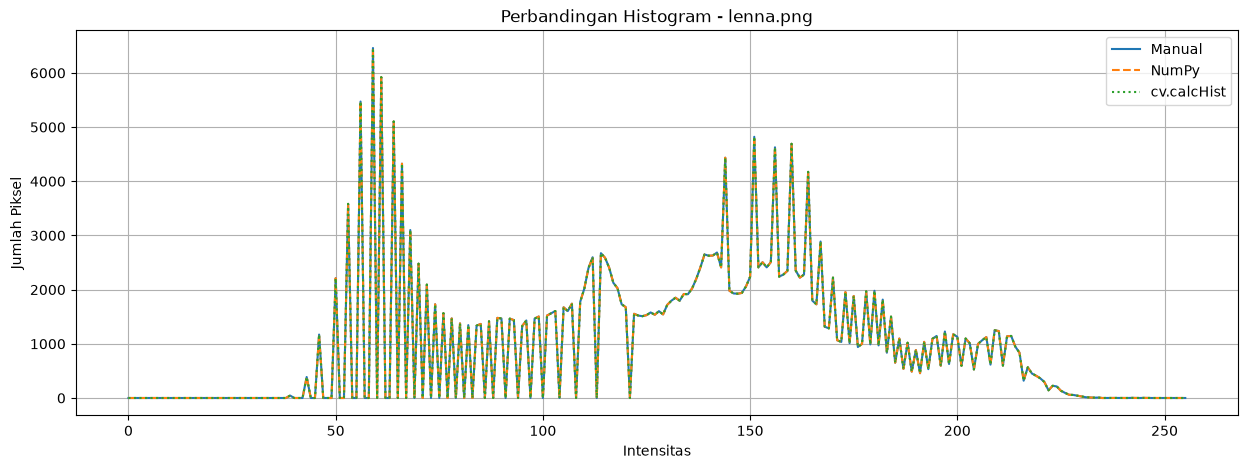

PEMBUKTIAN HISTOGRAM : KTM1b.jpeg
Selisih Manual vs NumPy      : 0
Selisih Manual vs cv.calcHist: 0
Selisih NumPy vs cv.calcHist : 0
Selisih maksimum             : 0
HASIL: KETIGA HISTOGRAM SAMA (SELISIH = 0)


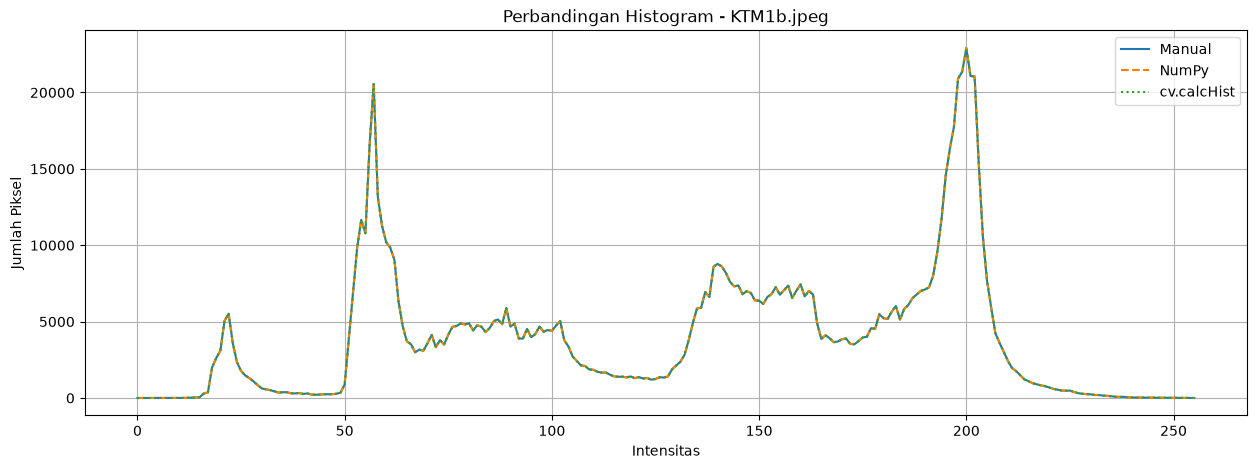

In [56]:
# ============================================================
# NOMOR 1
# Lena.jpg
# ============================================================
img_lena, hist_lena_manual, hist_lena_numpy, hist_lena_cv = \
    compare_histograms('lenna.png')


# ============================================================
# NOMOR 1
# KTM1b.jpg
# ============================================================
img_ktm1b, hist_ktm1b_manual, hist_ktm1b_numpy, hist_ktm1b_cv = \
    compare_histograms('KTM1b.jpeg')


# ============================================================
# FUNGSI HISTOGRAM TERNORMALISASI DAN CDF
# ============================================================
def normalized_histogram_and_cdf(img, bins=256):

    hist, bin_edges = np.histogram(
        img.ravel(),
        bins=bins,
        range=(0, 256)
    )

    # Histogram ternormalisasi p(j)
    p = hist / hist.sum()

    # CDF
    cdf = np.cumsum(p)

    return hist, p, cdf, bin_edges

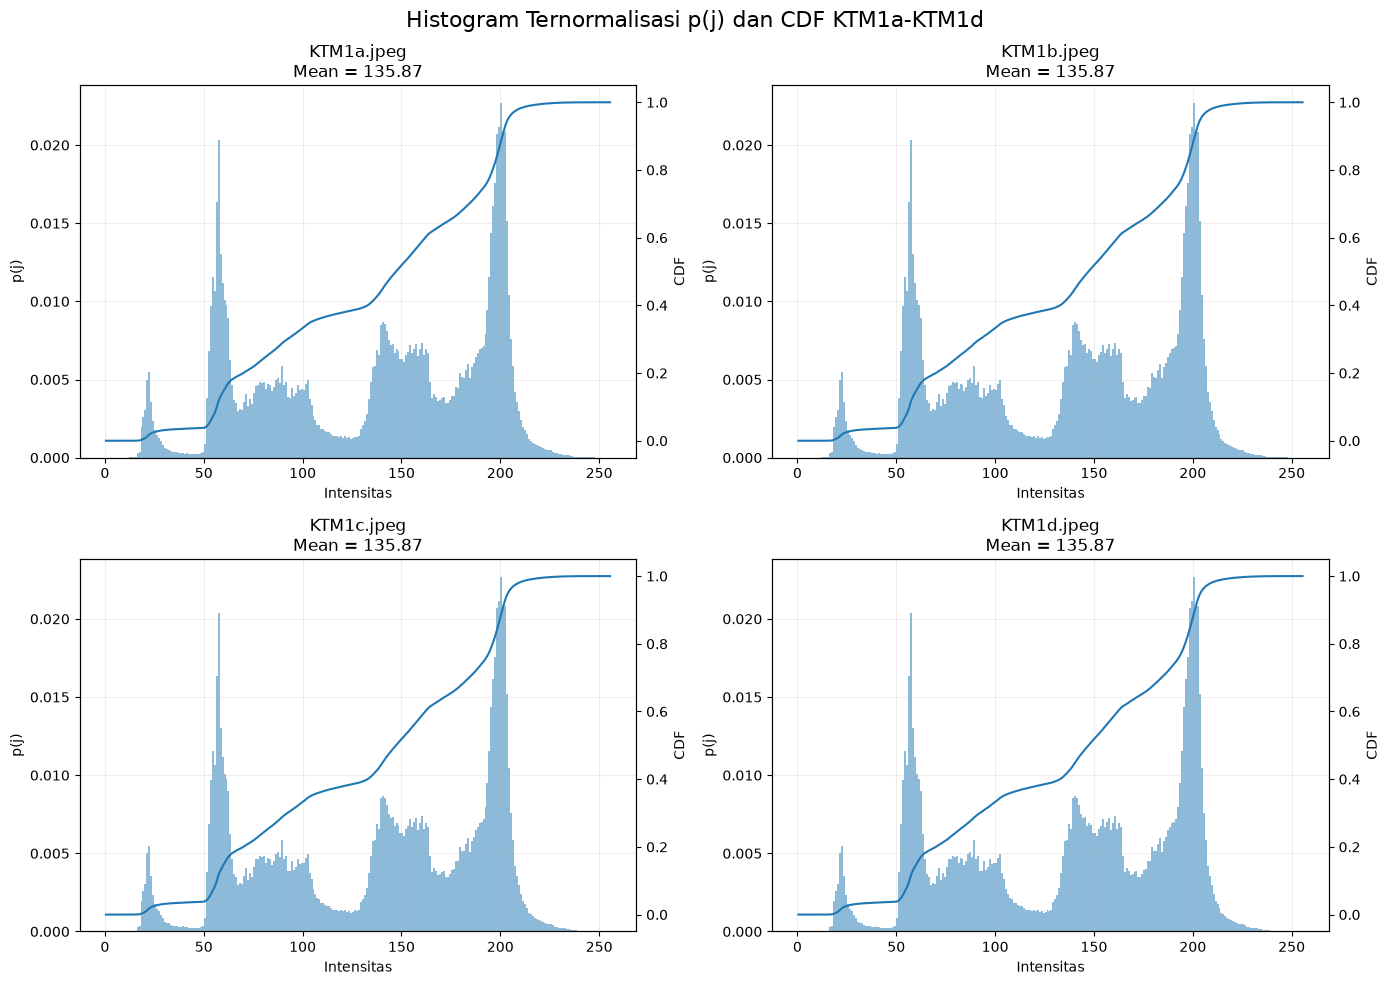

ANALISIS KECERAHAN CITRA
KTM1a.jpeg: mean intensitas = 135.87
KTM1b.jpeg: mean intensitas = 135.87
KTM1c.jpeg: mean intensitas = 135.87
KTM1d.jpeg: mean intensitas = 135.87

Citra paling gelap : KTM1a.jpeg
Citra paling terang: KTM1a.jpeg


In [57]:
# ============================================================
# NOMOR 2
# Histogram ternormalisasi dan CDF KTM1a - KTM1d
# dalam satu figure 2 x 2
# ============================================================

ktm_files = [
    'KTM1a.jpeg',
    'KTM1b.jpeg',
    'KTM1c.jpeg',
    'KTM1d.jpeg'
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10)
)

axes = axes.ravel()

mean_brightness = {}

for i, filename in enumerate(ktm_files):

    img = read_gray(filename)

    # Rata-rata intensitas untuk mengetahui
    # citra paling gelap dan paling terang
    mean_brightness[filename] = np.mean(img)

    hist, p, cdf, bin_edges = \
        normalized_histogram_and_cdf(img)

    # Titik tengah bin
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    ax = axes[i]

    # Histogram ternormalisasi
    ax.bar(
        bin_centers,
        p,
        width=1,
        alpha=0.5,
        label='p(j)'
    )

    # CDF
    ax2 = ax.twinx()

    ax2.plot(
        bin_centers,
        cdf,
        label='CDF'
    )

    ax.set_title(
        f'{filename}\nMean = {mean_brightness[filename]:.2f}'
    )

    ax.set_xlabel('Intensitas')
    ax.set_ylabel('p(j)')
    ax2.set_ylabel('CDF')

    ax.grid(alpha=0.2)

plt.suptitle(
    'Histogram Ternormalisasi p(j) dan CDF KTM1a-KTM1d',
    fontsize=16
)

plt.tight_layout()
plt.show()


# ============================================================
# MENENTUKAN CITRA PALING GELAP DAN PALING TERANG
# ============================================================

darkest = min(
    mean_brightness,
    key=mean_brightness.get
)

brightest = max(
    mean_brightness,
    key=mean_brightness.get
)

print("=" * 60)
print("ANALISIS KECERAHAN CITRA")
print("=" * 60)

for filename, mean in mean_brightness.items():
    print(f"{filename}: mean intensitas = {mean:.2f}")

print()
print("Citra paling gelap :", darkest)
print("Citra paling terang:", brightest)



In [58]:
h_numpy, _ = np.histogram(
    lena,
    bins=256,
    range=(0, 256)
)

In [59]:
h_cv = cv.calcHist(
    [lena],
    [0],
    None,
    [256],
    [0, 256]
).flatten()

In [60]:
selisih_numpy = np.max(
    np.abs(
        h_manual - h_numpy
    )
)

selisih_cv = np.max(
    np.abs(
        h_manual - h_cv
    )
)

print(
    'Selisih Manual vs NumPy:',
    selisih_numpy
)

print(
    'Selisih Manual vs OpenCV:',
    selisih_cv
)

Selisih Manual vs NumPy: 0
Selisih Manual vs OpenCV: 0.0


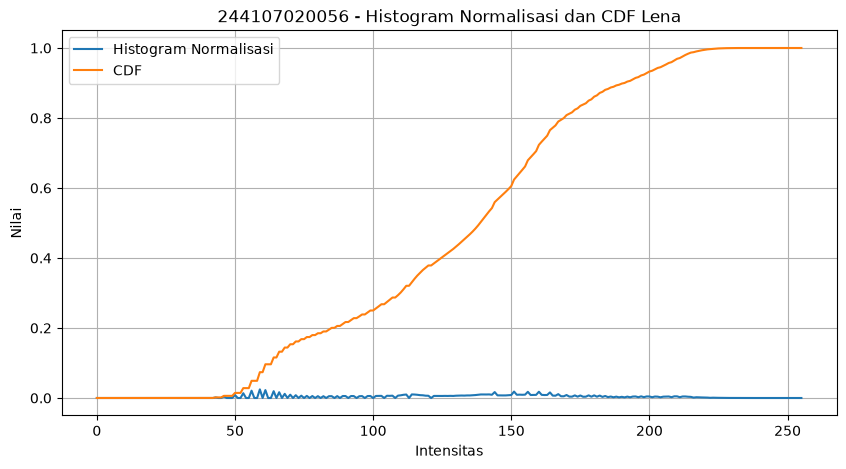

In [61]:
hist = histogram_manual(
    lena
)

p = hist / lena.size

cdf = np.cumsum(p)


plt.figure(
    figsize=(10, 5)
)

plt.plot(
    p,
    label='Histogram Normalisasi'
)

plt.plot(
    cdf,
    label='CDF'
)

plt.title(
    NIM + ' - Histogram Normalisasi dan CDF Lena'
)

plt.xlabel(
    'Intensitas'
)

plt.ylabel(
    'Nilai'
)

plt.legend()

plt.grid()

plt.show()

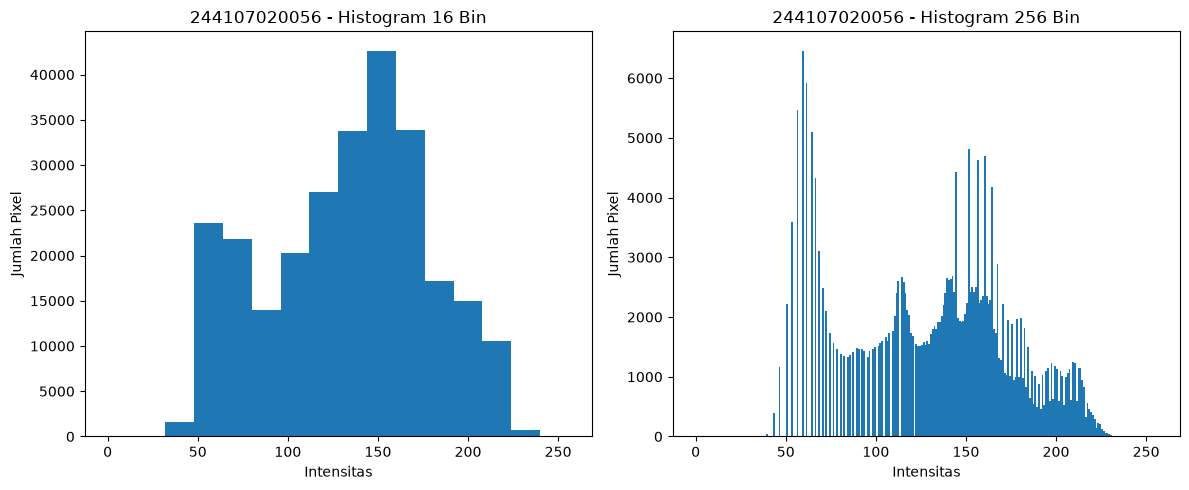

In [62]:
plt.figure(
    figsize=(12, 5)
)


plt.subplot(
    1,
    2,
    1
)

plt.hist(
    lena.ravel(),
    bins=PARAM['bins'],
    range=(0, 256)
)

plt.title(
    NIM +
    ' - Histogram ' +
    str(PARAM['bins']) +
    ' Bin'
)

plt.xlabel(
    'Intensitas'
)

plt.ylabel(
    'Jumlah Pixel'
)


plt.subplot(
    1,
    2,
    2
)

plt.hist(
    lena.ravel(),
    bins=256,
    range=(0, 256)
)

plt.title(
    NIM + ' - Histogram 256 Bin'
)

plt.xlabel(
    'Intensitas'
)

plt.ylabel(
    'Jumlah Pixel'
)

plt.tight_layout()

plt.show()

In [63]:


# ------------------------------------------------------------
# E-2.1 EQUALIZATION MANUAL
# ------------------------------------------------------------

hist = histogram_manual(
    lena
)

p = hist / lena.size

cdf = np.cumsum(p)

L = 256

transform = np.round(
    (L - 1) * cdf
).astype(np.uint8)

lena_equal_manual = (
    transform[lena]
)

In [64]:

# ------------------------------------------------------------
# E-2.2 EQUALIZATION OPENCV
# ------------------------------------------------------------

lena_equal_cv = cv.equalizeHist(
    lena
)


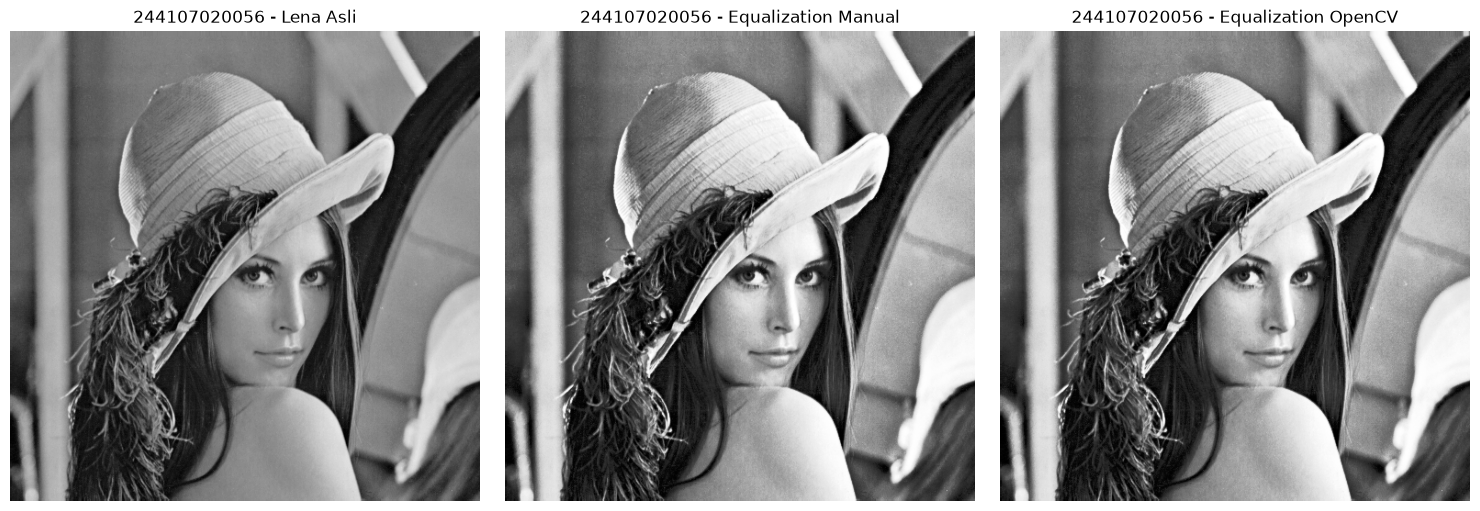

In [65]:

# ------------------------------------------------------------
# E-2.3 TAMPILKAN
# ------------------------------------------------------------

plt.figure(
    figsize=(15, 5)
)


plt.subplot(
    1,
    3,
    1
)

plt.imshow(
    lena,
    cmap='gray'
)

plt.title(
    NIM + ' - Lena Asli'
)

plt.axis('off')


plt.subplot(
    1,
    3,
    2
)

plt.imshow(
    lena_equal_manual,
    cmap='gray'
)

plt.title(
    NIM + ' - Equalization Manual'
)

plt.axis('off')


plt.subplot(
    1,
    3,
    3
)

plt.imshow(
    lena_equal_cv,
    cmap='gray'
)

plt.title(
    NIM + ' - Equalization OpenCV'
)

plt.axis('off')

plt.tight_layout()

plt.show()


In [66]:

# ------------------------------------------------------------
# E-2.4 SELISIH MANUAL VS OPENCV
# ------------------------------------------------------------

selisih_equalization = np.max(
    np.abs(
        lena_equal_manual.astype(np.int16)
        -
        lena_equal_cv.astype(np.int16)
    )
)

print(
    'Selisih Equalization Manual vs OpenCV:',
    selisih_equalization
)


# ============================================================
# E-2.5 EQUALIZATION CITRA BERWARNA
# ============================================================

lena_color = cv.imread(
    CONTOH
)

if lena_color is None:
    raise FileNotFoundError(
        'Lena.png tidak ditemukan!'
    )

Selisih Equalization Manual vs OpenCV: 1


In [67]:
# ------------------------------------------------------------
# B, G, R
# ------------------------------------------------------------

kanal = list(
    cv.split(lena_color)
)

for i in range(3):

    kanal[i] = cv.equalizeHist(
        kanal[i]
    )

he_rgb = cv.merge(
    kanal
)



In [68]:
# ------------------------------------------------------------
# YCrCb
# ------------------------------------------------------------

ycrcb = cv.cvtColor(
    lena_color,
    cv.COLOR_BGR2YCrCb
)

y, cr, cb = cv.split(
    ycrcb
)

he_y = cv.cvtColor(
    cv.merge([
        cv.equalizeHist(y),
        cr,
        cb
    ]),
    cv.COLOR_YCrCb2BGR
)

In [69]:
# ------------------------------------------------------------
# HSV
# ------------------------------------------------------------

hsv = cv.cvtColor(
    lena_color,
    cv.COLOR_BGR2HSV
)

h, sat, v = cv.split(
    hsv
)

he_v = cv.cvtColor(
    cv.merge([
        h,
        sat,
        cv.equalizeHist(v)
    ]),
    cv.COLOR_HSV2BGR
)

In [70]:

# ------------------------------------------------------------
# LAB
# ------------------------------------------------------------

lab = cv.cvtColor(
    lena_color,
    cv.COLOR_BGR2LAB
)

l, a, b = cv.split(
    lab
)

he_l = cv.cvtColor(
    cv.merge([
        cv.equalizeHist(l),
        a,
        b
    ]),
    cv.COLOR_LAB2BGR
)

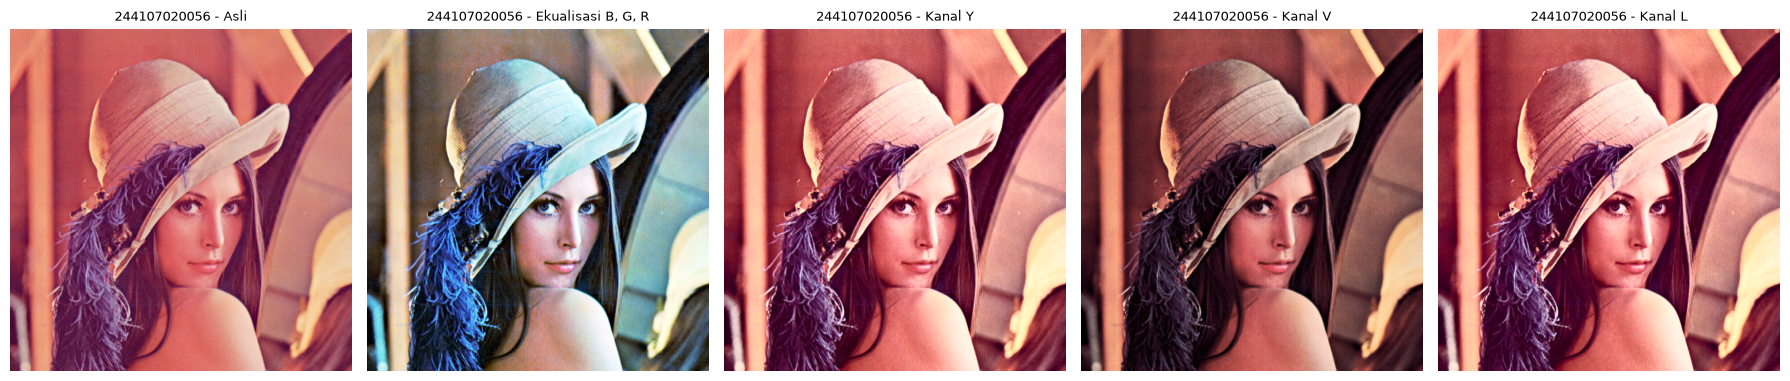

In [71]:
# ============================================================
# E-2.6 TAMPILKAN 5 HASIL
# ============================================================

judul = [
    'Asli',
    'Ekualisasi B, G, R',
    'Kanal Y',
    'Kanal V',
    'Kanal L'
]

citra = [
    lena_color,
    he_rgb,
    he_y,
    he_v,
    he_l
]

plt.figure(
    figsize=(18, 4)
)

for i, (c, t) in enumerate(
    zip(citra, judul),
    1
):

    plt.subplot(
        1,
        5,
        i
    )

    plt.imshow(
        cv.cvtColor(
            c,
            cv.COLOR_BGR2RGB
        )
    )

    plt.title(
        NIM + ' - ' + t,
        fontsize=9
    )

    plt.axis('off')

plt.tight_layout()

plt.show()


In [72]:

# ============================================================
# E-2.7 PERGESERAN HUE
# ============================================================

def geser_hue(
    asli,
    hasil
):

    h1 = cv.cvtColor(
        asli,
        cv.COLOR_BGR2HSV
    )[:, :, 0].astype(
        np.int16
    )

    h2 = cv.cvtColor(
        hasil,
        cv.COLOR_BGR2HSV
    )[:, :, 0].astype(
        np.int16
    )

    d = np.abs(
        h1 - h2
    )

    d = np.minimum(
        d,
        180 - d
    )

    return d.mean()


print('\nPergeseran Hue:')

for t, c in zip(
    judul,
    citra
):

    print(
        t,
        ':',
        round(
            geser_hue(
                lena_color,
                c
            ) * 2,
            2
        ),
        'derajat'
    )


Pergeseran Hue:
Asli : 0.0 derajat
Ekualisasi B, G, R : 74.86 derajat
Kanal Y : 2.02 derajat
Kanal V : 0.68 derajat
Kanal L : 2.61 derajat


In [73]:

# ============================================================
# E-2.8 CLAHE
# ============================================================

clahe = cv.createCLAHE(
    clipLimit=PARAM['clip'],
    tileGridSize=(
        PARAM['tile'],
        PARAM['tile']
    )
)

ycrcb = cv.cvtColor(
    lena_color,
    cv.COLOR_BGR2YCrCb
)

y, cr, cb = cv.split(
    ycrcb
)

y_clahe = clahe.apply(
    y
)

hasil_clahe = cv.cvtColor(
    cv.merge([
        y_clahe,
        cr,
        cb
    ]),
    cv.COLOR_YCrCb2BGR
)


plt.figure(
    figsize=(10, 5)
)


plt.subplot(
    1,
    2,
    1
)

plt.imshow(
    cv.cvtColor(
        lena_color,
        cv.COLOR_BGR2RGB
    )
)

plt.title(
    NIM + ' - Asli'
)

plt.axis('off')


plt.subplot(
    1,
    2,
    2
)

plt.imshow(
    cv.cvtColor(
        hasil_clahe,
        cv.COLOR_BGR2RGB
    )
)

plt.title(
    NIM + ' - CLAHE'
)

plt.axis('off')

plt.tight_layout()

plt.show()


print(
    'CLAHE clipLimit:',
    PARAM['clip']
)

print(
    'CLAHE tile:',
    PARAM['tile']
)


KeyError: 'clip'


E-3 DITHERING FLOYD-STEINBERG
Jumlah level L: 8


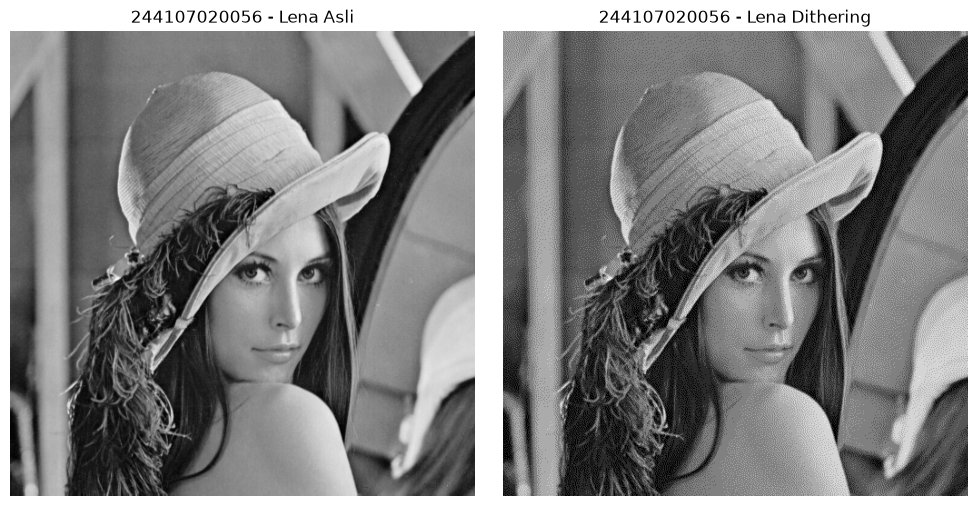

In [ ]:
# ============================================================
# E-3
# DITHERING FLOYD-STEINBERG
# ============================================================

print('\n==========================================')
print('E-3 DITHERING FLOYD-STEINBERG')
print('==========================================')


# ------------------------------------------------------------
# E-3.1 DITHERING LENA
# ------------------------------------------------------------

hasil_dither = floyd_steinberg(
    lena,
    L=PARAM['L']
)

print(
    'Jumlah level L:',
    PARAM['L']
)


plt.figure(
    figsize=(10, 5)
)


plt.subplot(
    1,
    2,
    1
)

plt.imshow(
    lena,
    cmap='gray'
)

plt.title(
    NIM + ' - Lena Asli'
)

plt.axis('off')


plt.subplot(
    1,
    2,
    2
)

plt.imshow(
    hasil_dither,
    cmap='gray'
)

plt.title(
    NIM + ' - Lena Dithering'
)

plt.axis('off')

plt.tight_layout()

plt.show()

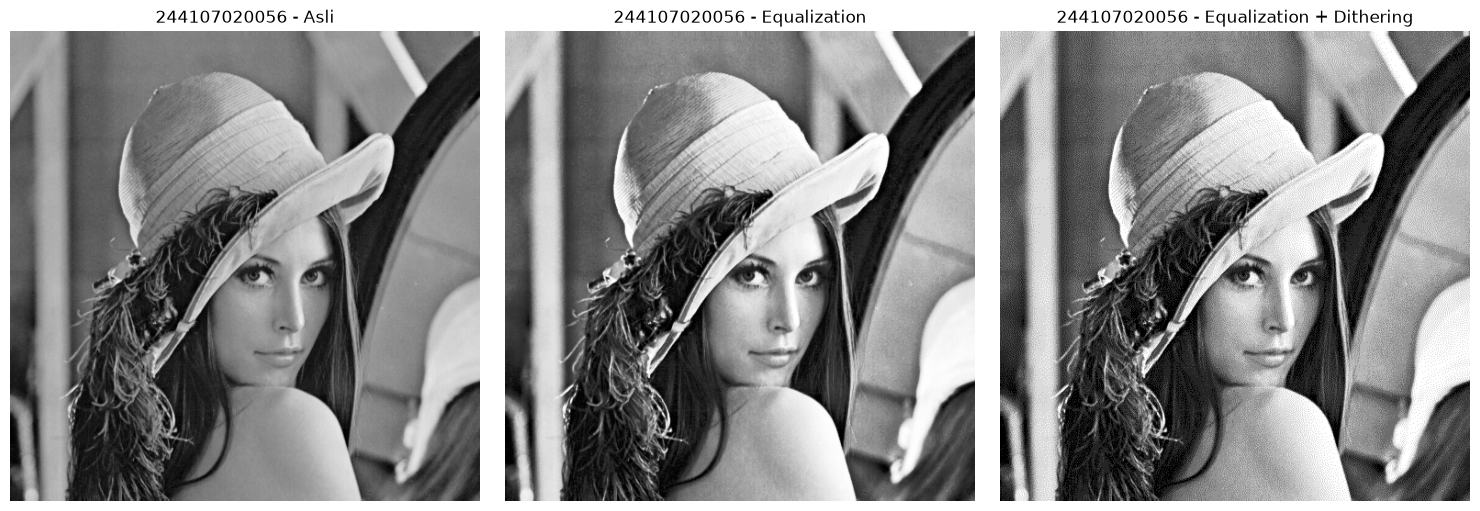


PRAKTIKUM MODUL 5 SELESAI


In [ ]:
# ============================================================
# E-3.2 EQUALIZATION + DITHERING
# ============================================================

hasil_equal_dither = floyd_steinberg(
    lena_equal_cv,
    L=PARAM['L']
)


plt.figure(
    figsize=(15, 5)
)


plt.subplot(
    1,
    3,
    1
)

plt.imshow(
    lena,
    cmap='gray'
)

plt.title(
    NIM + ' - Asli'
)

plt.axis('off')


plt.subplot(
    1,
    3,
    2
)

plt.imshow(
    lena_equal_cv,
    cmap='gray'
)

plt.title(
    NIM + ' - Equalization'
)

plt.axis('off')


plt.subplot(
    1,
    3,
    3
)

plt.imshow(
    hasil_equal_dither,
    cmap='gray'
)

plt.title(
    NIM + ' - Equalization + Dithering'
)

plt.axis('off')

plt.tight_layout()

plt.show()


# ============================================================
# SELESAI
# ============================================================

print('\n==========================================')
print('PRAKTIKUM MODUL 5 SELESAI')
print('==========================================')